# Testing & Evaluation - Credit Card Fraud Detection

**Deskripsi Proyek:** Mengoptimalkan **threshold keputusan** menggunakan validation set, lalu mengevaluasi performa akhir secara unbiased pada test set.

### Install Library

In [1]:
pip install -q xgboost

### Import Library

In [2]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import xgboost as xgb

from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve)

### Mount Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 1. Load Model & Data

In [4]:
PROCESSED_DIR = '/content/drive/MyDrive/Fraud Detection/data/processed'
MODELS_DIR = '/content/drive/MyDrive/Fraud Detection/models'

def load_pkl(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

# Load model XGBoost (tanpa redefine class)
booster = xgb.Booster()
booster.load_model(os.path.join(MODELS_DIR, 'xgb_model.json'))
best_iter = booster.best_iteration
N_TREES = (int(best_iter) + 1) if best_iter is not None else None

v_cols = [f'V{i}' for i in range(1, 29)]
FEATURES = v_cols + ['Amount_log', 'Time_hour', 'Time_day']


def predict_margin(X):
    X_df = pd.DataFrame(np.asarray(X), columns=FEATURES)
    d = xgb.DMatrix(X_df)
    if N_TREES is None:
        return booster.predict(d, output_margin=True)
    return booster.predict(d, output_margin=True, iteration_range=(0, N_TREES))

# Load Data
X_val_scaled = load_pkl(os.path.join(PROCESSED_DIR, 'X_val_scaled.pkl'))
X_test_scaled = load_pkl(os.path.join(PROCESSED_DIR, 'X_test_scaled.pkl'))
y_val = load_pkl(os.path.join(PROCESSED_DIR, 'y_val.pkl'))
y_test = load_pkl(os.path.join(PROCESSED_DIR, 'y_test.pkl'))

y_val = np.asarray(y_val)
y_test = np.asarray(y_test)

print('Model & data dimuat.')
print(f'X_val_scaled  : {X_val_scaled.shape} | fraud {int(y_val.sum())}')
print(f'X_test_scaled : {X_test_scaled.shape} | fraud {int(y_test.sum())}')
print(f'Model         : xgb_model.json | n_trees={N_TREES}')

Model & data dimuat.
X_val_scaled  : (42559, 31) | fraud 71
X_test_scaled : (42559, 31) | fraud 71
Model         : xgb_model.json | n_trees=362


### 2. Predict Function

In [5]:
def predict_proba(X):
    margin = predict_margin(X)
    return 1.0 / (1.0 + np.exp(-margin))

### 2. Threshold Optimization

In [6]:
xgb_val_proba = predict_proba(X_val_scaled)

# Precision-Recall curve pada validation
precisions, recalls, thresholds = precision_recall_curve(y_val, xgb_val_proba)

# F1 per threshold
f1_scores = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)
best_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[best_idx]
optimal_f1 = f1_scores[best_idx]

print(f'Optimal Threshold = {optimal_threshold:.4f} (F1 maksimum di validation = {optimal_f1:.4f})')

Optimal Threshold = 0.8328 (F1 maksimum di validation = 0.8548)


### 3. Threshold Result

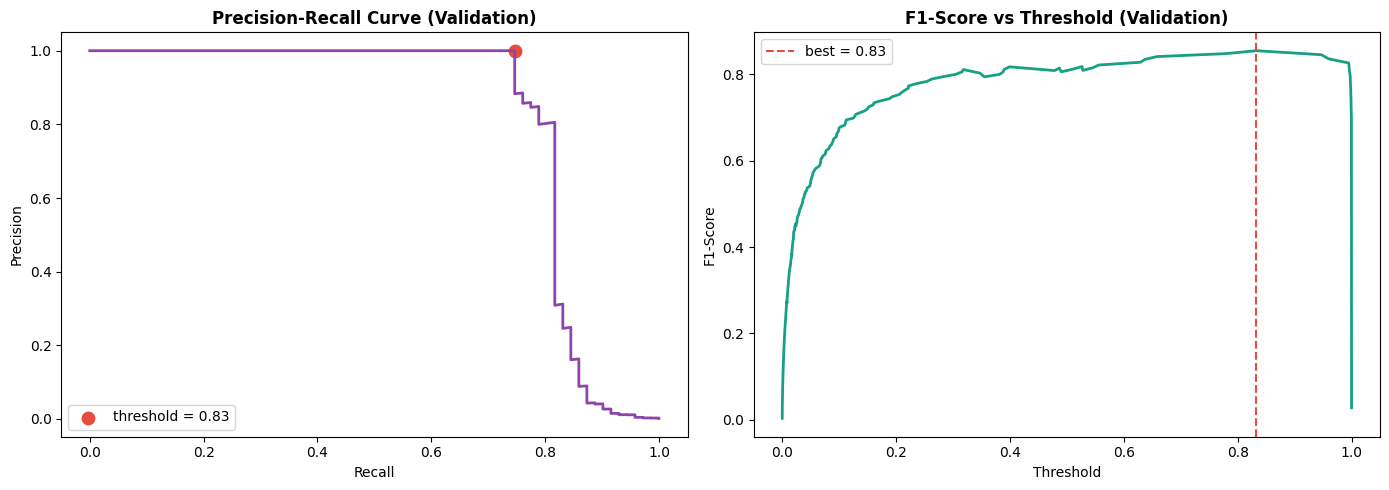

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(recalls, precisions, color='#8e44ad', lw=2)
axes[0].scatter(recalls[best_idx], precisions[best_idx], color='#e74c3c', s=80,
                label=f'threshold = {optimal_threshold:.2f}')
axes[0].set_title('Precision-Recall Curve (Validation)', fontweight='bold')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend()

axes[1].plot(thresholds, f1_scores, color='#16a085', lw=2)
axes[1].axvline(optimal_threshold, color='#e74c3c', linestyle='--',
                label=f'best = {optimal_threshold:.2f}')
axes[1].set_title('F1-Score vs Threshold (Validation)', fontweight='bold')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('F1-Score')
axes[1].legend()

plt.tight_layout()
plt.show()

### 4. Save Threshold

In [8]:
threshold_path = os.path.join(MODELS_DIR, 'threshold.pkl')
with open(threshold_path, 'wb') as f:
    pickle.dump({
        'optimal_threshold': float(optimal_threshold),
        'optimal_f1_val': float(optimal_f1),
    }, f)

print(f'Saved: {threshold_path}')

Saved: /content/drive/MyDrive/Fraud Detection/models/threshold.pkl


### 3. Testing

In [9]:
xgb_test_proba = predict_proba(X_test_scaled)
xgb_test_pred = (xgb_test_proba >= optimal_threshold).astype(int)

print('Prediksi test set selesai.')

Prediksi test set selesai.


### 4. Confusion Matrix

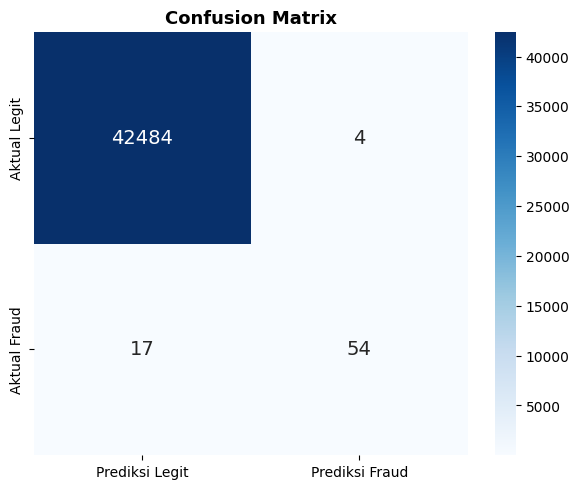

TP (fraud terdeteksi): 54
FN (fraud terlewat)  : 17
FP (alarm palsu)     : 4
TN (legit normal)    : 42484


In [10]:
cm = confusion_matrix(y_test, xgb_test_pred)
TP, FN = cm[1, 1], cm[1, 0]
FP, TN = cm[0, 1], cm[0, 0]

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Legit', 'Prediksi Fraud'],
            yticklabels=['Aktual Legit', 'Aktual Fraud'],
            annot_kws={'size': 14}, ax=ax)
ax.set_title('Confusion Matrix', fontsize=13, fontweight='bold')
plt.show()

print(f'TP (fraud terdeteksi): {TP}')
print(f'FN (fraud terlewat)  : {FN}')
print(f'FP (alarm palsu)     : {FP}')
print(f'TN (legit normal)    : {TN}')

### 5. Performance Metrics Results

In [11]:
# Classification metrics
precision = precision_score(y_test, xgb_test_pred)
recall = recall_score(y_test, xgb_test_pred)
f1 = f1_score(y_test, xgb_test_pred)
roc_auc = roc_auc_score(y_test, xgb_test_proba)
pr_auc = average_precision_score(y_test, xgb_test_proba)

# Business metrics
fraud_detection_rate = TP / (TP + FN)
false_alarm_rate = FP / (FP + TN)

metrics = pd.DataFrame({
    'Metric': ['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC',
               'Fraud Detection Rate (TPR)', 'False Alarm Rate (FPR)'],
    'Value': [precision, recall, f1, roc_auc, pr_auc,
              fraud_detection_rate, false_alarm_rate]
}).round(4)

print('Performance Metrics Results:')
print(metrics.to_string(index=False))

Performance Metrics Results:
                    Metric  Value
                 Precision 0.9310
                    Recall 0.7606
                  F1-Score 0.8372
                   ROC-AUC 0.9715
                    PR-AUC 0.7878
Fraud Detection Rate (TPR) 0.7606
    False Alarm Rate (FPR) 0.0001


### 6. Threshold Comparison (0.5 vs Optimal)

In [13]:
def evaluate_threshold(preds):
    cm_tmp = confusion_matrix(y_test, preds)
    tp_t, fn_t = cm_tmp[1, 1], cm_tmp[1, 0]
    fp_t, tn_t = cm_tmp[0, 1], cm_tmp[0, 0]
    return {
        'Precision': round(precision_score(y_test, preds), 4),
        'Recall': round(recall_score(y_test, preds), 4),
        'F1': round(f1_score(y_test, preds), 4),
        'FDR (%)': round(tp_t / (tp_t + fn_t) * 100, 4),
        'FAR (%)': round(fp_t / (fp_t + tn_t) * 100, 4),
    }

pred_05 = (xgb_test_proba >= 0.5).astype(int)

threshold_cmp = pd.DataFrame({
    'Threshold': ['Threshold default (0.5)', 'Threshold optimal (validation)'],
    'Value': [0.5, round(optimal_threshold, 4)],
}).join(
    pd.DataFrame([evaluate_threshold(pred_05), evaluate_threshold(xgb_test_pred)])
)

print(threshold_cmp.to_string(index=False))

                     Threshold  Value  Precision  Recall     F1  FDR (%)  FAR (%)
       Threshold default (0.5) 0.5000      0.806  0.7606 0.7826  76.0563   0.0306
Threshold optimal (validation) 0.8328      0.931  0.7606 0.8372  76.0563   0.0094


### 7. ROC & Precision-Recall Curves

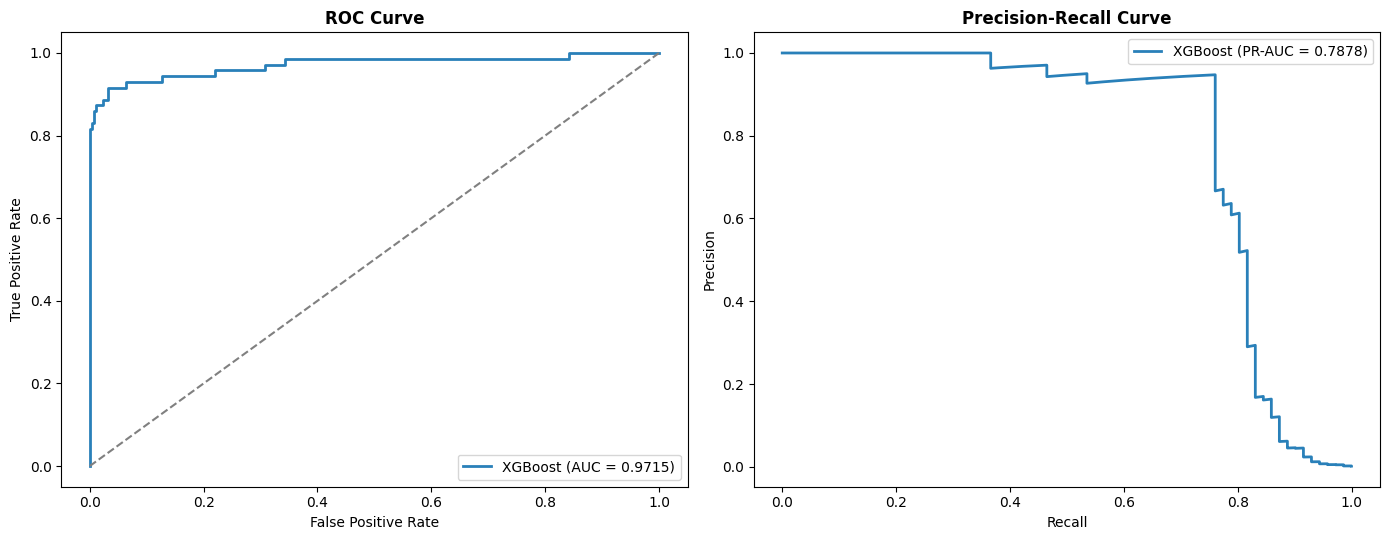

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, xgb_test_proba)
axes[0].plot(fpr, tpr, lw=2, color='#2980b9',
             label=f'XGBoost (AUC = {roc_auc_score(y_test, xgb_test_proba):.4f})')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[0].set_title('ROC Curve', fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

# Precision-Recall curve
pr_vals, rec_vals, _ = precision_recall_curve(y_test, xgb_test_proba)
axes[1].plot(rec_vals, pr_vals, lw=2, color='#2980b9',
             label=f'XGBoost (PR-AUC = {average_precision_score(y_test, xgb_test_proba):.4f})')
axes[1].set_title('Precision-Recall Curve', fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.show()

#### 4.3 Error Analysis (False Positives & False Negatives)

Ringkasan error pada test set:
  FP (alarm palsu)    : 4
  FN (fraud terlewat) : 17

Karakteristik skor per kelompok:
                       xgb_proba
error                           
FN (fraud terlewat)       0.0437
FP (alarm palsu)          0.9677
TN                        0.0006
TP (fraud terdeteksi)     0.9963

Perbandingan fitur terpenting (nilai sudah distandarisasi):
 Feature  Mean FP (alarm palsu)  Mean TN (normal)
     V14                 -4.609             0.015
     V10                 -3.167             0.006
      V4                  1.886            -0.012
Time_day                  0.015            -0.009
     V12                 -4.372             0.011


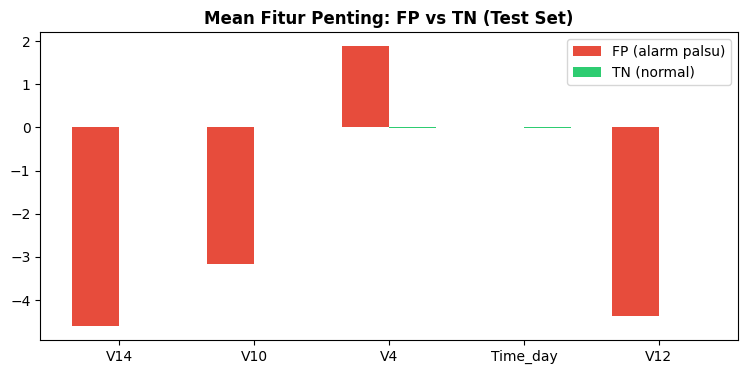

In [15]:
mask_fp = (y_test == 0) & (xgb_test_pred == 1)
mask_fn = (y_test == 1) & (xgb_test_pred == 0)
mask_tp = (y_test == 1) & (xgb_test_pred == 1)
mask_tn = (y_test == 0) & (xgb_test_pred == 0)

err_df = pd.DataFrame({
    'true_label': y_test,
    'xgb_proba': xgb_test_proba,
    'prediction': xgb_test_pred,
    'error': np.where(mask_fn, 'FN (fraud terlewat)',
               np.where(mask_fp, 'FP (alarm palsu)',
               np.where(mask_tp, 'TP (fraud terdeteksi)', 'TN'))),
})

print('Ringkasan error pada test set:')
print(f'  FP (alarm palsu)    : {mask_fp.sum()}')
print(f'  FN (fraud terlewat) : {mask_fn.sum()}')
print()

print('Karakteristik skor per kelompok:')
print(err_df.groupby('error')[['xgb_proba']].mean().round(4))
print()

# Bandingkan fitur terpenting pada FP vs TN (top-5 dari gain XGBoost)
top_k = 5
gain_imp = booster.get_score(importance_type='gain')
top_feat_names = sorted(gain_imp, key=gain_imp.get, reverse=True)[:top_k]
top_feats = [FEATURES.index(f) for f in top_feat_names]
X_test_np = np.asarray(X_test_scaled)

feat_compare = pd.DataFrame({
    'Feature': [X_test_scaled.columns[i] for i in top_feats],
    'Mean FP (alarm palsu)': X_test_np[mask_fp][:, top_feats].mean(axis=0),
    'Mean TN (normal)': X_test_np[mask_tn][:, top_feats].mean(axis=0),
}).round(3)

print('Perbandingan fitur terpenting (nilai sudah distandarisasi):')
print(feat_compare.to_string(index=False))

if mask_fp.sum() > 0 and mask_tn.sum() > 0:
    fig, ax = plt.subplots(figsize=(9, 4))
    width = 0.35
    x = np.arange(top_k)
    ax.bar(x - width / 2, feat_compare['Mean FP (alarm palsu)'], width,
           label='FP (alarm palsu)', color='#e74c3c')
    ax.bar(x + width / 2, feat_compare['Mean TN (normal)'], width,
           label='TN (normal)', color='#2ecc71')
    ax.set_xticks(x)
    ax.set_xticklabels(feat_compare['Feature'])
    ax.set_title('Mean Fitur Penting: FP vs TN (Test Set)', fontweight='bold')
    ax.legend()
    plt.show()